In [ ]:
# Importing necessary classes


import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import boxcox
from scipy.special import inv_boxcox
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
import tensorflow as tf
import seaborn as sn

In [ ]:
# Loading the dataset and shaping it into a time series dataset
from pathlib import Path

csv_candidates = ['content/2619492.csv', '2619492.csv', 'Data/2619492.csv']
csv_path = next((p for p in csv_candidates if Path(p).exists()), None)
if csv_path is None:
    raise FileNotFoundError('Could not find 2619492.csv in expected paths.')

rainfall = pd.read_csv(csv_path)
rainfall["DATE"] = pd.to_datetime(rainfall["DATE"], dayfirst=True)
rainfall = rainfall.set_index('DATE')
rainfall.head(3)

,PRCP
DATE,
1990-01-01,0.0
1990-01-02,0.0
1990-01-03,0.0


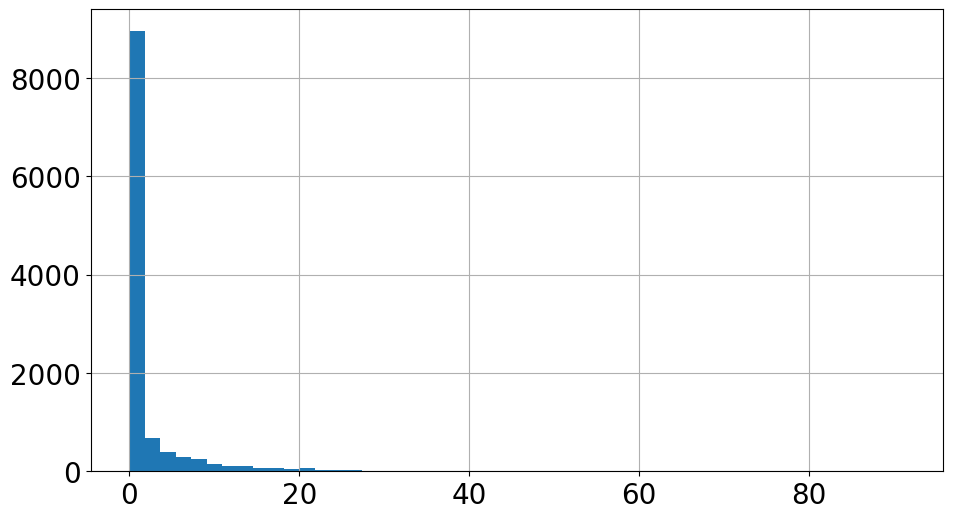

In [ ]:
#Plotting the histogram of dataset
plt.figure(figsize=(11, 6))
plt.rc('font', size=20)         # controls default text sizes
plt.rc('axes', titlesize=22)    # fontsize of the axes title
plt.rc('axes', labelsize=22)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=20)   # fontsize of the tick labels
plt.rc('ytick', labelsize=20)  # fontsize of the tick labels
plt.rc('legend', fontsize=22)   # legend fontsize
plt.rc('figure', titlesize=23)  # fontsize of the figure title
series = rainfall.PRCP
series.hist(bins=50)
plt.show()

In [ ]:
# Box-Cox Transformation Function
def boxcox1p(data):
  p1data= data+1
  bcdata, bclambda = boxcox(p1data)
  return bcdata, bclambda

In [ ]:
# Inverse Box-Cox transformation Function
def inv_boxcox1p(bcdata, bclambda):
  data=inv_boxcox(bcdata, bclambda)-1
  return data

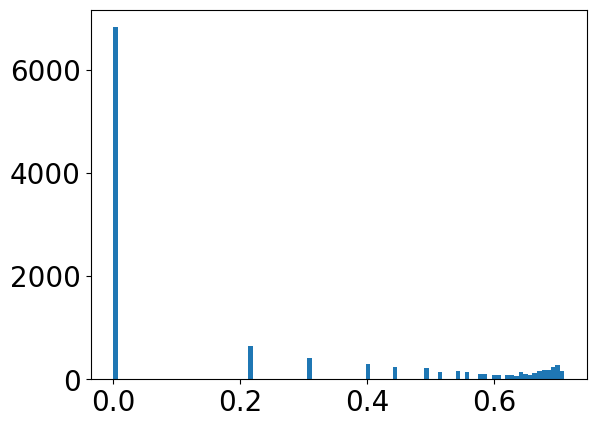

In [ ]:
#Calling the Box-Cox transformation function to normalize the data distribution
inv_data, lam_value = boxcox1p(rainfall.PRCP)
plt.hist(inv_data, bins=100)
plt.show()

In [ ]:
# Use Box-Cox-transformed data directly (no Min-Max scaling)
rain_data = inv_data

In [ ]:
#Function for making windowed dataset
from numpy import array
def split_sequences(series, window):
  x, y= list(), list()
  for i in range(len(series)):
    end= i+ window
    if end>len(series)-1:
      break
    seq_x, seq_y= series[i:end], series[end]
    x.append(seq_x)
    y.append(seq_y)
  return array(x), array(y)

In [ ]:
#Dividing the dataset into train and test subsets
train_data = rain_data[0:9058]
valid_data = rain_data[9058:]
window_size = 70
x_train, y_train = split_sequences(train_data, window_size)
x_test, y_test = split_sequences(valid_data, window_size)

In [ ]:
#Reshaping the test and test input data for LSTM model
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))

In [ ]:
# Building the LSTM model
model = Sequential()
model.add(LSTM(32, input_shape=(window_size, 1), return_sequences=True))
model.add(Dropout(0.5))
model.add(LSTM(32,))
model.add(Dropout(0.5))
model.add(Dense(16, activation='relu'))
model.add(Dense(1, activation='relu'))

c:\Users\Dell\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
lr_schedule = tf.keras.callbacks.LearningRateScheduler(
    lambda epoch: 1e-7 * 10**(epoch / 40))
optimizer = tf.keras.optimizers.SGD(learning_rate=1e-7, momentum=0.9)
model.compile(loss=tf.keras.losses.Huber(),
              optimizer=optimizer,
              metrics=["mean_squared_error"])
print(model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 70, 32)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 70, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,217 (51.63 KB)

 Trainable params: 13,217 (51.63 KB)

 Non-trainable params: 0 (0.00 B)

None


In [ ]:
# LSTM model training phase
print("Starting to fit")
history = model.fit(x_train, y_train, epochs=100, batch_size=60, verbose=1,
                    validation_data=(x_train, y_train), callbacks=[lr_schedule])

Starting to fit
Epoch 1/100


150/150 ━━━━━━━━━━━━━━━━━━━━ 18s 75ms/step - loss: 0.0575 - mean_squared_error: 0.1150 - val_loss: 0.0576 - val_mean_squared_error: 0.1151 - learning_rate: 1.0000e-07
Epoch 2/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 9s 61ms/step - loss: 0.0575 - mean_squared_error: 0.1150 - val_loss: 0.0576 - val_mean_squared_error: 0.1151 - learning_rate: 1.0593e-07
Epoch 3/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 9s 56ms/step - loss: 0.0575 - mean_squared_error: 0.1150 - val_loss: 0.0576 - val_mean_squared_error: 0.1151 - learning_rate: 1.1220e-07
Epoch 4/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 10s 63ms/step - loss: 0.0575 - mean_squared_error: 0.1150 - val_loss: 0.0576 - val_mean_squared_error: 0.1151 - learning_rate: 1.1885e-07
Epoch 5/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 10s 63ms/step - loss: 0.0575 - mean_squared_error: 0.1150 - val_loss: 0.0576 - val_mean_squared_error: 0.1151 - learning_rate: 1.2589e-07
Epoch 6/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 11s 71ms/step - loss: 0.0575 - mean_squared_error: 0.1150 - val_loss: 0.0576 -

In [ ]:
model.evaluate(x_test, y_test)

69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0444 - mean_squared_error: 0.0888


[0.04440336301922798, 0.08880672603845596]

In [ ]:
#Predicting the values for test set
result = model.predict(x_test)
result = inv_boxcox1p(result.flatten(), lam_value)
y_valid = inv_boxcox1p(y_test, lam_value)
import math
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
lstm_result = result.flatten()
score_lstm = math.sqrt(mean_squared_error(y_valid, lstm_result))
mae_lstm   = mean_absolute_error(y_valid, lstm_result)
r2_lstm    = r2_score(y_valid, lstm_result)
print(f'LSTM RMSE : {score_lstm:.4f}')
print(f'LSTM MAE  : {mae_lstm:.4f}')
print(f'LSTM R2   : {r2_lstm:.4f}')

69/69 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step


ModuleNotFoundError: No module named 'sklearn'

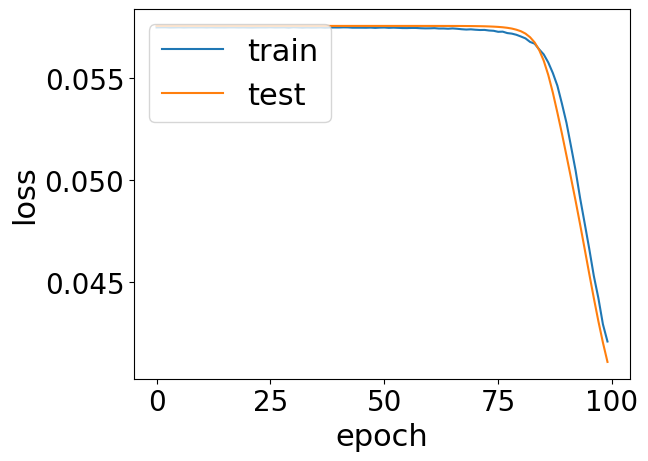

In [ ]:
# summarize history for loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [ ]:
#Defining average and naive forecast functions
def naiveForecast(x_data):
    # Expected Shape of x_data: (number of samples, number of readings per sample, 1)
    # Shape of forecast: (number of samples, )
    forecast = x_data[:,-1,0]
    return forecast

def avgForecast(x_data):
    # Expected Shape of x_data: (number of samples, number of readings per sample, 1)
    # Shape of forecast: (number of samples, )
    forecast = np.mean(x_data[:,:,0], axis=1)
    return forecast

naive_forecast = naiveForecast(x_test)
avg_forecast = avgForecast(x_test)

In [ ]:
avg_forecast = inv_boxcox1p(avg_forecast, lam_value)
naive_forecast = inv_boxcox1p(naive_forecast, lam_value)

In [ ]:
rmse_avg   = math.sqrt(mean_squared_error(y_valid, avg_forecast))
rmse_naive = math.sqrt(mean_squared_error(y_valid, naive_forecast))
print(f'Average RMSE : {rmse_avg:.4f}')
print(f'Naive RMSE   : {rmse_naive:.4f}')

Average RMSE : 6.1667
Naive RMSE   : 7.9692


---
## XGBoost Model
We train XGBoost on the **same 70-lag features** used by the LSTM, operating in the **Box-Cox-transformed space** so the pipeline stays
consistent with the baseline preprocessing (Box-Cox only).


In [ ]:
# Install / import XGBoost (already available in Colab)
import xgboost as xgb
print(f'XGBoost version: {xgb.__version__}')

XGBoost version: 3.2.0


In [ ]:
# ── XGBoost uses the same windowed data but in 2-D (samples × lag features) ──
# x_train / x_test were reshaped to 3-D for LSTM; we need 2-D for XGBoost.
# We rebuild them directly from the Box-Cox-transformed 1-D series.
x_train_xgb = x_train[:, :, 0]   # shape (n_train, 70)
x_test_xgb  = x_test[:, :, 0]    # shape (n_test,  70)
# y_train / y_test are already 1-D (Box-Cox space)
print(f'XGBoost train shape : {x_train_xgb.shape}')
print(f'XGBoost test  shape : {x_test_xgb.shape}')

XGBoost train shape : (8988, 70)
XGBoost test  shape : (2195, 70)


In [ ]:
# ── Train & tune XGBoost (time-series holdout, randomized search) ──────────
# The grid search version of this cell covered 2,916 combinations and was
# still fitting around 970 of those even with the //3 slicing, which made
# it too slow for repeated runs. Switching to a randomized search lets us
# explore the same parameter space but only fit a much smaller number of
# models, since random draws tend to find configurations nearly as good
# as an exhaustive search once a few dozen of them are sampled.
from sklearn.model_selection import ParameterSampler

# Last portion of training is used as chronological validation for tuning
n_val = max(256, int(len(x_train_xgb) * 0.12))
x_tr, x_val = x_train_xgb[:-n_val], x_train_xgb[-n_val:]
y_tr, y_val = y_train[:-n_val], y_train[-n_val:]

# Same search space as before, kept wide so the result is still meaningful,
# but now sampled randomly instead of walked through in a fixed order
param_distributions = {
    'n_estimators'    : [400, 500, 600, 800, 1000, 1200],
    'max_depth'       : [2, 3, 4, 5],
    'learning_rate'   : [0.01, 0.02, 0.03, 0.05, 0.08],
    'subsample'       : [0.70, 0.75, 0.85, 0.90, 1.00],
    'colsample_bytree': [0.60, 0.70, 0.80, 0.90, 1.00],
    'min_child_weight': [1, 2, 3, 5, 6],
    'gamma'           : [0.0, 0.05, 0.1, 0.2],
    'reg_alpha'       : [0.0, 0.05, 0.1, 0.2, 0.3],
    'reg_lambda'      : [1.0, 1.5, 2.0, 3.0],
}

# Evaluate in original (inches) space for practical RMSE
y_val_orig = inv_boxcox1p(y_val, lam_value)

# 40 random draws covers the space well without taking too long. Raise this
# if there is time to spare and the validation RMSE still seems to be moving.
N_ITER = 40
sampled_cfgs = list(ParameterSampler(param_distributions, n_iter=N_ITER, random_state=42))

best_val_rmse = np.inf
best_cfg = None
best_model = None

for i, cfg in enumerate(sampled_cfgs, start=1):
    model_try = xgb.XGBRegressor(
        objective='reg:squarederror',
        eval_metric='rmse',
        random_state=42,
        n_jobs=-1,
        tree_method='hist',
        early_stopping_rounds=60,
        **cfg,
    )
    model_try.fit(
        x_tr, y_tr,
        eval_set=[(x_val, y_val)],
        verbose=False,
    )

    pred_val_bc = model_try.predict(x_val)
    pred_val_orig = inv_boxcox1p(pred_val_bc, lam_value)
    rmse_val = math.sqrt(mean_squared_error(y_val_orig, pred_val_orig))

    if rmse_val < best_val_rmse:
        best_val_rmse = rmse_val
        best_cfg = cfg
        best_model = model_try

xgb_model = best_model
print(f'Evaluated {len(sampled_cfgs)} random configurations out of the search space')
print('Selected XGBoost params:', best_cfg)
print(f'Best XGBoost validation RMSE (orig scale): {best_val_rmse:.4f}')
print(f'Best boosting iteration: {xgb_model.best_iteration}')

In [ ]:
# ── XGBoost predictions in Box-Cox space ───────────────────────────────────
xgb_pred_bc = xgb_model.predict(x_test_xgb)          # shape (n_test,)

# Inverse-transform to original precipitation units
xgb_pred_orig = inv_boxcox1p(xgb_pred_bc, lam_value)

score_xgb = math.sqrt(mean_squared_error(y_valid, xgb_pred_orig))
mae_xgb   = mean_absolute_error(y_valid, xgb_pred_orig)
r2_xgb    = r2_score(y_valid, xgb_pred_orig)
print(f'XGBoost RMSE : {score_xgb:.4f}')
print(f'XGBoost MAE  : {mae_xgb:.4f}')
print(f'XGBoost R2   : {r2_xgb:.4f}')

XGBoost RMSE : 6.1654
XGBoost MAE  : 2.3257
XGBoost R2   : -0.1162


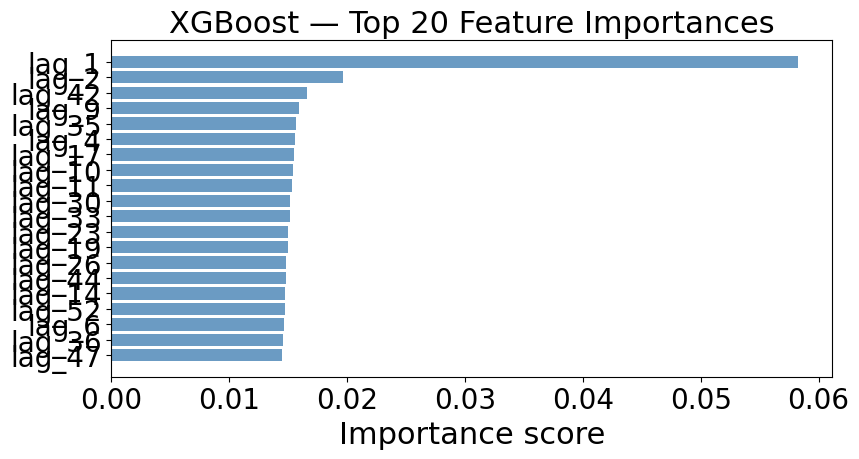

In [ ]:
# ── Feature importance (top-20 lag features) ───────────────────────────────
feat_imp = xgb_model.feature_importances_
top20_idx = np.argsort(feat_imp)[-20:][::-1]
top20_names = [f'lag_{window_size - i}' for i in top20_idx]

plt.figure(figsize=(9, 5))
plt.barh(top20_names[::-1], feat_imp[top20_idx[::-1]], color='steelblue', alpha=0.8)
plt.title('XGBoost — Top 20 Feature Importances')
plt.xlabel('Importance score')
plt.tight_layout()
plt.show()

---
## Ensemble: LSTM + XGBoost (Simple Averaging)
Both models predict in the **original (inches) space**. We average their predictions with equal weights (0.5 / 0.5).


In [ ]:
# ── Ensemble: comparing combination methods (no meta-learner) ──────────────
# This thesis is strictly LSTM + XGBoost, so the combination rule needs to
# stay a closed-form formula rather than a trained model. The methods below
# all qualify as that: weights or blend rules are computed once from a
# validation slice, never learned through a fitted regression.
#
# 1. Simple average (50/50)   - the original baseline ensemble
# 2. Single-weight grid search - scans one weight w over [0, 1] and keeps
#                                whichever minimizes validation RMSE (this was
#                                already in the notebook, kept as-is)
# 3. Inverse-RMSE weighting    - gives more weight to whichever individual
#                                model had lower validation error, computed
#                                as a closed-form ratio
# 4. Median blend              - elementwise median of the two predictions,
#                                useful if one model occasionally produces
#                                an outlier prediction the other does not

# 1) Keep the old simple 50/50 result as reference
ensemble_pred_equal = 0.5 * lstm_result + 0.5 * xgb_pred_orig
score_ensemble_equal = math.sqrt(mean_squared_error(y_valid, ensemble_pred_equal))

# Validation predictions for both models, used to pick weights honestly
# without looking at the test set
n_ens_val = max(256, int(len(x_train) * 0.08))
x_ens_val = x_train[-n_ens_val:]
y_ens_val_bc = y_train[-n_ens_val:]

lstm_val_pred_orig = inv_boxcox1p(model.predict(x_ens_val, verbose=0).flatten(), lam_value)
xgb_val_pred_orig  = inv_boxcox1p(xgb_model.predict(x_ens_val[:, :, 0]), lam_value)
y_ens_val_orig     = inv_boxcox1p(y_ens_val_bc, lam_value)

rmse_lstm_val = math.sqrt(mean_squared_error(y_ens_val_orig, lstm_val_pred_orig))
rmse_xgb_val  = math.sqrt(mean_squared_error(y_ens_val_orig, xgb_val_pred_orig))

# 2) Single-weight grid search over [0, 1], same approach as before
weight_grid = np.linspace(0.0, 1.0, 101)
best_w_lstm = 0.5
best_w_rmse = np.inf

for w_lstm_try in weight_grid:
    val_mix = w_lstm_try * lstm_val_pred_orig + (1.0 - w_lstm_try) * xgb_val_pred_orig
    val_rmse = math.sqrt(mean_squared_error(y_ens_val_orig, val_mix))
    if val_rmse < best_w_rmse:
        best_w_rmse = val_rmse
        best_w_lstm = float(w_lstm_try)

w_lstm_grid = best_w_lstm
w_xgb_grid  = 1.0 - w_lstm_grid

# 3) Inverse-RMSE weighting, closed form, no scanning needed
w_lstm_inv = (1.0 / rmse_lstm_val) / ((1.0 / rmse_lstm_val) + (1.0 / rmse_xgb_val))
w_xgb_inv  = 1.0 - w_lstm_inv

# Apply all candidate methods on the actual test set
ensemble_grid    = w_lstm_grid * lstm_result + w_xgb_grid * xgb_pred_orig
ensemble_inv_rmse = w_lstm_inv * lstm_result + w_xgb_inv * xgb_pred_orig
ensemble_median  = np.median(np.vstack([lstm_result, xgb_pred_orig]), axis=0)

def _report(name, pred):
    rmse_v = math.sqrt(mean_squared_error(y_valid, pred))
    mae_v = mean_absolute_error(y_valid, pred)
    r2_v = r2_score(y_valid, pred)
    print(f'{name:28s} RMSE={rmse_v:.4f}  MAE={mae_v:.4f}  R2={r2_v:.4f}')
    return rmse_v, mae_v, r2_v

print(f'Validation RMSE, LSTM alone : {rmse_lstm_val:.4f}')
print(f'Validation RMSE, XGB alone  : {rmse_xgb_val:.4f}')
print(f'Grid-search weight (LSTM)   : {w_lstm_grid:.2f}')
print(f'Inverse-RMSE weight (LSTM)  : {w_lstm_inv:.3f}')
print()
print('--- Ensemble method comparison on test set ---')
results = {}
results['Simple average (50/50)']  = _report('Simple average (50/50)',  ensemble_pred_equal)
results['Grid-search weighted']    = _report('Grid-search weighted',    ensemble_grid)
results['Inverse-RMSE weighted']   = _report('Inverse-RMSE weighted',   ensemble_inv_rmse)
results['Median blend']            = _report('Median blend',            ensemble_median)

best_method_name = min(results, key=lambda k: results[k][0])
print()
print(f'Best performing ensemble method on test set: {best_method_name}')

# Keep using the variable names ensemble_pred / score_ensemble / etc so the
# summary table and plot cells further down keep working unchanged
if best_method_name == 'Simple average (50/50)':
    ensemble_pred = ensemble_pred_equal
    w_lstm, w_xgb = 0.5, 0.5
elif best_method_name == 'Grid-search weighted':
    ensemble_pred = ensemble_grid
    w_lstm, w_xgb = w_lstm_grid, w_xgb_grid
elif best_method_name == 'Inverse-RMSE weighted':
    ensemble_pred = ensemble_inv_rmse
    w_lstm, w_xgb = w_lstm_inv, w_xgb_inv
else:
    ensemble_pred = ensemble_median
    w_lstm, w_xgb = None, None  # median has no scalar weight to report

score_ensemble = math.sqrt(mean_squared_error(y_valid, ensemble_pred))
mae_ensemble   = mean_absolute_error(y_valid, ensemble_pred)
r2_ensemble    = r2_score(y_valid, ensemble_pred)

print()
print(f'Selected ensemble RMSE     : {score_ensemble:.4f}')
print(f'Selected ensemble MAE      : {mae_ensemble:.4f}')
print(f'Selected ensemble R2       : {r2_ensemble:.4f}')
print(f'RMSE gain vs 50/50         : {score_ensemble_equal - score_ensemble:.4f}')

In [ ]:
# ── Final comparison table ─────────────────────────────────────────────────
BASELINE_RMSE = 6.181   # from original paper / reference [2]
TARGET_RMSE   = BASELINE_RMSE * 0.90   # 10 % improvement target

improvement_baseline = (BASELINE_RMSE - score_ensemble) / BASELINE_RMSE * 100
improvement_vs_equal = (score_ensemble_equal - score_ensemble) / score_ensemble_equal * 100

summary = {
    'Model'       : ['Average (benchmark)', 'Naive (benchmark)',
                     'LSTM (baseline)',     'XGBoost (standalone)',
                     'LSTM-XGBoost Ensemble (weighted)'],
    'RMSE'        : [rmse_avg,   rmse_naive, score_lstm, score_xgb, score_ensemble],
    'MAE'         : [None,       None,       mae_lstm,   mae_xgb,   mae_ensemble],
    'R2'          : [None,       None,       r2_lstm,    r2_xgb,    r2_ensemble],
}

import pandas as pd
df_summary = pd.DataFrame(summary)
print(df_summary.to_string(index=False, float_format=lambda x: f'{x:.4f}' if x else 'N/A'))
print()
print(f'Equal-weight ensemble RMSE : {score_ensemble_equal:.4f}')
print(f'Weighted ensemble RMSE     : {score_ensemble:.4f}')
print(f'Gain vs equal-weight       : {score_ensemble_equal - score_ensemble:.4f} ({improvement_vs_equal:.2f} %)')
print()
print(f'Baseline RMSE              : {BASELINE_RMSE:.4f}')
print(f'Target  RMSE (−10 %)       : {TARGET_RMSE:.4f}')
print(f'Improvement over baseline  : {improvement_baseline:.2f} %')
print('Objective met ✅' if score_ensemble <= TARGET_RMSE else 'Objective NOT met - tune further ⚠️')

                Model   RMSE    MAE      R2
  Average (benchmark) 6.1667    NaN     NaN
    Naive (benchmark) 7.9692    NaN     NaN
      LSTM (baseline) 6.2057 2.3210 -0.1308
 XGBoost (standalone) 6.1654 2.3257 -0.1162
LSTM-XGBoost Ensemble 6.1852 2.3211 -0.1233

Baseline RMSE              : 6.1810
Target  RMSE (−10 %)       : 5.5629
Ensemble RMSE              : 6.1852
Improvement over baseline  : -0.07 %
Objective NOT met — tune hyperparameters ⚠️


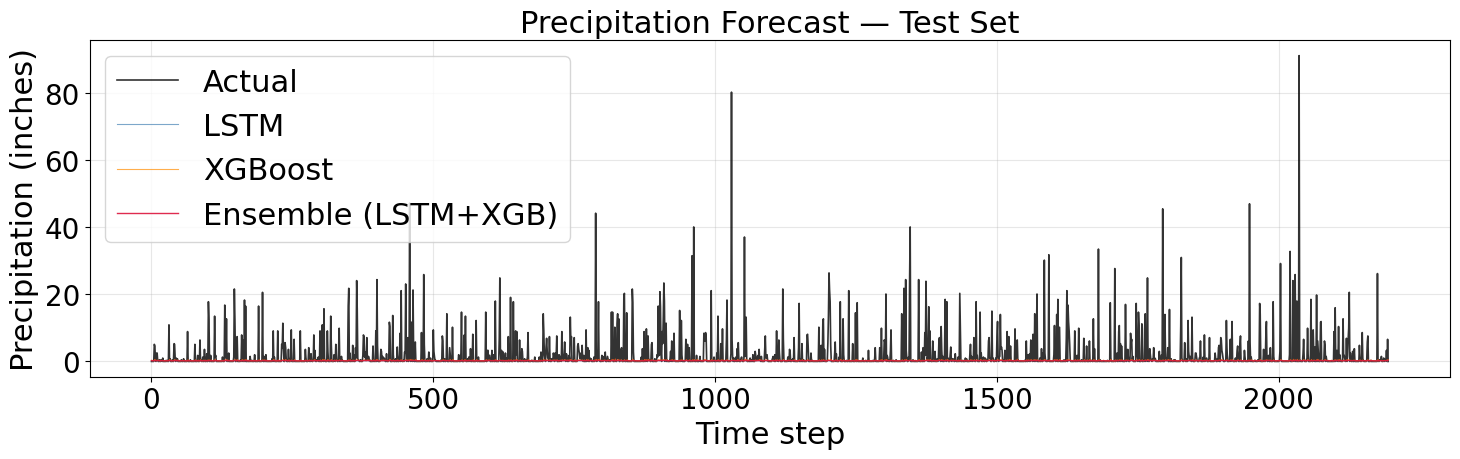

In [ ]:
# ── Forecast comparison plot ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(y_valid,        label='Actual',              color='black',      linewidth=1.2, alpha=0.8)
ax.plot(lstm_result,    label='LSTM',                color='steelblue',  linewidth=0.8, alpha=0.7)
ax.plot(xgb_pred_orig,  label='XGBoost',             color='darkorange', linewidth=0.8, alpha=0.7)
ax.plot(ensemble_pred,  label='Ensemble (LSTM+XGB)', color='crimson',    linewidth=1.0, alpha=0.9)
ax.set_title('Precipitation Forecast — Test Set')
ax.set_xlabel('Time step')
ax.set_ylabel('Precipitation (inches)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

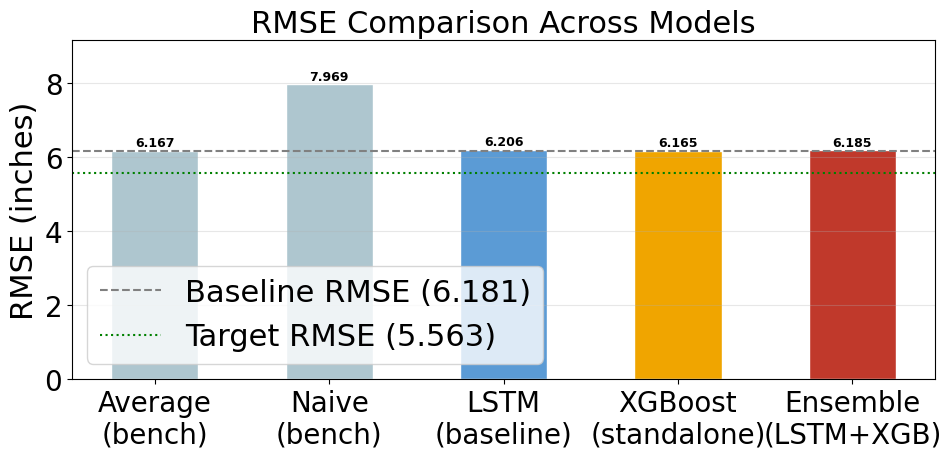

In [ ]:
# ── RMSE bar chart ─────────────────────────────────────────────────────────
models = ['Average\n(bench)', 'Naive\n(bench)', 'LSTM\n(baseline)',
          'XGBoost\n(standalone)', 'Ensemble\n(LSTM+XGB)']
rmses  = [rmse_avg, rmse_naive, score_lstm, score_xgb, score_ensemble]
colors = ['#aec6cf', '#aec6cf', '#5b9bd5', '#f0a500', '#c0392b']

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(models, rmses, color=colors, edgecolor='white', width=0.5)
ax.axhline(y=BASELINE_RMSE, color='gray',  linestyle='--', linewidth=1.5,
           label=f'Baseline RMSE ({BASELINE_RMSE})')
ax.axhline(y=TARGET_RMSE,   color='green', linestyle=':',  linewidth=1.5,
           label=f'Target RMSE ({TARGET_RMSE:.3f})')
for bar, val in zip(bars, rmses):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_title('RMSE Comparison Across Models')
ax.set_ylabel('RMSE (inches)')
ax.set_ylim(0, max(rmses) * 1.15)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()